## Introducción

Este cuaderno implementa el cálculo de la función de autocorrelación $G(t)$ del campo dipolar magnético generado por la difusión de moléculas cerca de un centro NV (nitrogen-vacancy) en diamante, en el contexto del Nano-NMR.

El modelo resuelve la ecuación de difusión con un perfil inhomogéneo $D(z)$ en coordenadas cilíndricas $(\rho, z)$:

$$D(z) = D_s + (D_0 - D_s)\left[\left(1 - e^{-\lambda(z-d)}\right)(1 - S(z)) + S(z)\right],$$

donde $S(z) = \tfrac{1}{2}\left[1 + \tanh\!\left(\tfrac{z - (z_c + d)}{\delta}\right)\right]$ es una función de transición suave. Los parámetros físicos son: $d = 15\,\text{nm}$ (profundidad del NV), $D_0 = 2\times10^3\,\text{nm}^2/\mu\text{s}$, $D_s = 2\times10^1\,\text{nm}^2/\mu\text{s}$, $R = L = 50d = 750\,\text{nm}$.

La solución se obtiene mediante expansión modal en funciones de Bessel radiales $J_0(\alpha_n \rho)$ y modos axiales numéricos, con 100 modos radiales y 100 modos axiales, usando una malla adaptativa tipo sinh ($\alpha_\text{grid} = 5$, $N_z = 90\,000$ nodos) y paralelización con `joblib` (4 núcleos).

In [1]:
import numpy as np
from scipy.special import jv, jn_zeros
from scipy.sparse.linalg import eigsh, ArpackNoConvergence
from scipy.linalg import eigh_tridiagonal
from scipy.sparse import diags, identity
from scipy.interpolate import interp1d, CubicSpline
from scipy.optimize import fsolve, brentq
from scipy.integrate import quad
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LogNorm

# Solución de la ecuación de difusión para un coeficiente $D(z)$ variable

## Parámetros físicos

In [2]:
##############################################################################
# 1. Parámetros Físicos (en nanómetros)
##############################################################################
# Conversión: 1 m = 1e9 nm.
d = 15               # Profundidad del NV en nm
D0 = 2e3             # 2e-9 * 1e18     # 2e-9 m²/us -> 2e9 nm²/s
D_s = 2e1            # nm^2/us
R = L = 50*d         # 50 d = 750 nm
delta = 2*d/3        # 10 nm (ancho de la transición tanh)
lambda_param = 0.75/d  # 0.05 nm⁻¹ (tasa de recuperación exponencial)
n_modes_radial = 100  # Cantidad de modos de R(ρ)
m_max = 100           # Cantidad de modos de Z(z)
N_r = N_z = 90000    # Número de nodos en r y z
alpha_grid = 5.0     # Aglomeramiento de nodos cerca de z=0
varkappa = 0.0       # nm/µs — permeabilidad de la BC de Robin en z = d
z_c = 2.5*d           # 37.5 nm — altura crítica, medida desde z = d
# (antes: z_c = lambda_param*L, dimensionalmente inconsistente
#  —nm⁻¹·nm es adimensional—; 2.5*d da el mismo valor, 37.5 nm)

## Malla adaptativa en $z$
Para el caso de la coordenada $z$, se opta por una malla que tenga una mayor concentración de nodos cerca de $z=0$ y que el espaciado entre estos aumente conforme $z>0$. Esto permite resolver los gradientes fuertes de $D(z)$ cerca de la superficie. Para hacer esto, se realiza una transformación hiperbólica para concentrar los nodos, como en la ecuación:
                
$$z_j=d+L\cdot \frac{\sinh{\left(\alpha_\mathrm{grid}\cdot\frac{j}{N_{z}-1}\right)}}{\sinh{\alpha_\mathrm{grid}}},\quad j\in\left[0,N_{z}-1\right]$$

Donde $\alpha_\mathrm{grid}\in\mathbb{N}$ es el parámetro de estiramiento, un factor que se encarga de controlar la densidad de nodos cerca de la superficie ($z\to0$), permitiendo una resolución espacial ajustada, $N_z$ es el número total de nodos y $L$ es la altura máxima en $z$.

De esta forma el espaciado entre nodos se calculará como:

$$h_j=z_j-z_{j-1},\,\forall\,j=1,2,\dots,N_z-1,\quad h_{j+1/2}=\frac{h_{j+1}+h_j}{2}$$

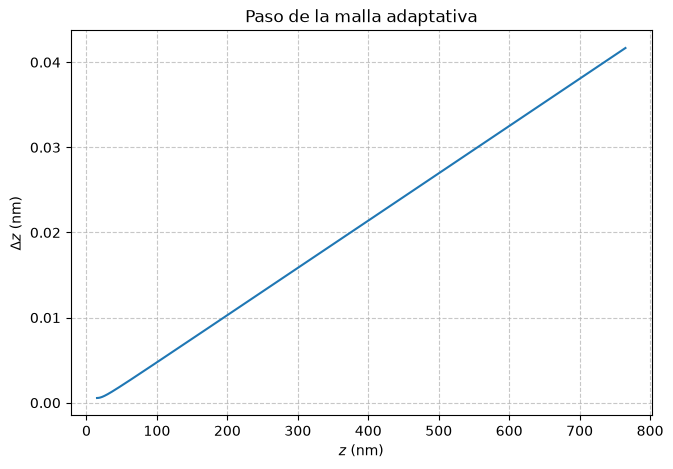

In [3]:
##############################################################################
# 2. Generación de la malla en z (nm)
##############################################################################

j_vals = np.arange(N_z)
z=d+L* np.sinh(alpha_grid * j_vals / (N_z - 1)) / np.sinh(alpha_grid)

plt.figure(figsize=(7.5,5))
plt.plot(z[1:],np.diff(z))
plt.xlabel(r"$z$ (nm)")
plt.ylabel(r"$\Delta z$ (nm)")
plt.title("Paso de la malla adaptativa")
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/Grid.pdf', bbox_inches='tight')
plt.show()
plt.close()

## Perfil de difusión
Para evitar discontinuidades en $D(z)$, se introduce una transición suave basada en $\tanh{}$, que es diferenciable y evita inestabilidades numéricas:

$$D(z)=D_s+(D_0-D_s)\left[\left(1-\exp{\left(-\lambda(z-d)\right)}\right)\cdot\left(1-S(z)\right)+S(z)\right],\quad S(z)=\frac{1}{2}\left(1+\tanh{\left(\frac{z-(z_c+d)}{\delta}\right)}\right)$$

Donde $D_s$ es la difusividad mínima en la superficie ($D(d)=D_s$), $D_0$ es la difusividad de bulk ($D\to D_0$ para $z\gg z_c+d$), $d$ es la profundidad del NV (el dominio del fluido empieza en $z=d$), $z_c$ es la altura crítica de transición (medida desde $z=d$) y $\delta\ll z_c$ es el ancho de la transición suave.

In [4]:
##############################################################################
# 3. Función de Difusión Global D(z) (z en nm)
##############################################################################
def D(z_val):
    """Perfil de difusión completo con z en nm.

       D(z) = D_s + (D0 - D_s) [ (1 - exp(-λ(z-d)))(1 - S(z)) + S(z) ],
       S(z) = 0.5 [1 + tanh((z - (z_c + d))/δ)].

       Cumple D(d) = D_s y D → D0 para z >> z_c + d.
    """
    S = 0.5 * (1 + np.tanh((z_val - (z_c+d)) / delta))
    # return D0 * ((1-np.exp(-lambda_param * z_val)) * (1 - S) + S)
    return D_s+(D0-D_s) * ((1-np.exp(-lambda_param * (z_val-d))) * (1 - S) + S)

En la figura a continuación se muestra el perfil propuesto utilizando algunos parámetros seleccionados de forma arbitraria.

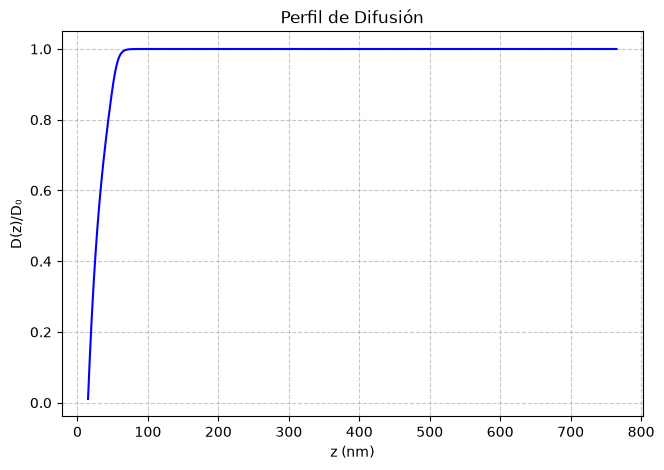

In [5]:
# Perfil de difusión
D_values = D(z)

plt.figure(figsize=(7.5,5))
plt.plot(z, D_values/D0, 'b-', lw=1.5)
plt.xlabel('z (nm)')
plt.ylabel('D(z)/D₀')
plt.title('Perfil de Difusión')
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/Dz_profile.pdf', bbox_inches='tight')
plt.show()
plt.close()

## Solución radial
l término radial se puede tomar constante también, para lo cual se toma $-\alpha^2$, de forma tal que:
    
$$\frac{1}{\rho \mathcal{R}}\left[\frac{d\mathcal{R}}{d\rho}+\rho\frac{d^2\mathcal{R}}{d\rho^2}\right]=-\alpha^2$$

Que al multiplicar por $\rho^2$ y simplificar, se obtiene una forma similar a la forma estándar de Bessel de orden cero:

$$\rho^2\frac{d^2\mathcal{R}}{d\rho^2}+\rho\frac{d\mathcal{R}}{d\rho}+\rho^2\alpha^2\mathcal{R}=0$$

Tomando un cambio de variable tal que $x=\alpha\rho$, $\frac{d\mathcal{R}}{d\rho}=\alpha\frac{d\mathcal{R}}{dx}$ y $\frac{d^2\mathcal{R}}{d\rho^2}=\alpha^2\frac{d^2\mathcal{R}}{dx^2}$, al reemplazar en la ecuación original:

$$\frac{x^2}{\alpha^2}\alpha^2\frac{d^2\mathcal{R}}{dx^2}+\frac{x}{\alpha}\alpha\frac{d\mathcal{R}}{dx}+\frac{x^2}{\alpha^2}\alpha^2\mathcal{R}=0$$

Lo que nos lleva a la forma estándar de Bessel de orden cero:

$$x^2\frac{d^2\mathcal{R}}{dx^2}+x\frac{d\mathcal{R}}{dx}+x^2\mathcal{R}=0$$

Esta ecuación tiene como solución una combinación de funciones de Bessel de primera y segunda categoría:

$$\mathcal{R}(x)=AJ_0(x)+BY_0(x)$$

Debido a que $Y_0(x)$ presenta una singularidad cuando $x\to0$, se toma que $B=0$, por lo que la solución estaría dada como:

$$\mathcal{R}(\rho)=AJ_0(\alpha\rho)$$

Al aplicar la condición de contorno de **Neumann** (pared reflejante, flujo nulo) en $\rho=R$:

$$\left.\frac{d\mathcal{R}}{d\rho}\right\vert_{\rho=R}=0\;\Rightarrow\;-\alpha J_1(\alpha R)=0\;\Rightarrow\; J_1(\alpha R)=0$$

Los ceros de $J_1$ se denotan $j_{1,n}$ ($n=1,2,\dots$), por lo que $\alpha_n=\frac{j_{1,n}}{R}$. La condición física es de no-flujo radial en la pared del cilindro, no una condición de absorción. Esto nos lleva a la serie donde cada modo $n$ corresponde a un valor propio $\alpha_n$:

$$\mathcal{R}_n(\rho)=A_nJ_0\left(\frac{j_{1,n}}{R}\rho\right)$$

De tal forma que la solución para la parte radial está dada por la serie de Fourier-Bessel de la ecuación:

$$\mathcal{R}(\rho)=\sum_{n=1}^\infty A_nJ_0\left(\frac{j_{1,n}}{R}\rho\right)$$

El $A_n$ se integrará con los valores de $T_0$ de la solución temporal y los coeficientes de expansión axiales.

In [6]:
##############################################################################
# 4. Solución Radial R(ρ)
##############################################################################

# Promedio armónico de D(z) sobre [d, d+L]:  D_eff = L / ∫ dz/D(z)
integral_D = np.trapezoid(1/D_values,z)
D_eff = L / integral_D
D_eff

np.float64(1792.5876372901728)

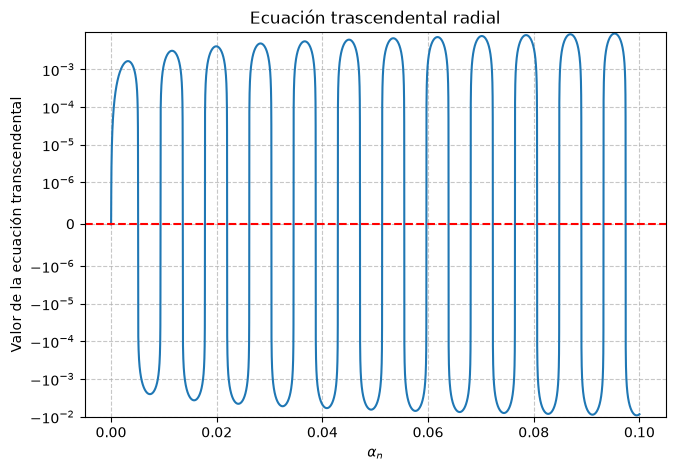

In [7]:
# Solución de la ecuación trascendental

def robin_eq(alpha):
    return alpha * jv(1, alpha * R) - (varkappa / D_eff) * jv(0, alpha * R)

plt.figure(figsize=(7.5,5))
alpha_plot=np.linspace(0,0.1,N_r)
plt.plot(alpha_plot,robin_eq(alpha_plot))
# plt.legend()
plt.title("Ecuación trascendental radial")
plt.ylabel("Valor de la ecuación transcendental")
plt.xlabel(r"$\alpha_n$")
plt.axhline(0, color='red', linestyle='--')
plt.yscale('symlog', linthresh=1e-6)
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/transcendental_radial.pdf', bbox_inches='tight')
plt.show()

In [8]:
# Estimar raíces con brentq en intervalos [a, b] con cambio de signo
alpha_min = 0.0
alpha_n = []
step = 0.0001  # Paso inicial para buscar raíces

alpha_current = alpha_min
while len(alpha_n) < n_modes_radial:
    # Buscar raíces en el intervalo [Lambda_current, Lambda_current + step]
    try:
        root = brentq(robin_eq, alpha_current, alpha_current + step, xtol=1e-6)
        alpha_n.append(root)
        alpha_current = root + step  # Mover el inicio para la próxima búsqueda
    except ValueError:
        alpha_current += step
alpha_n=np.array(alpha_n)

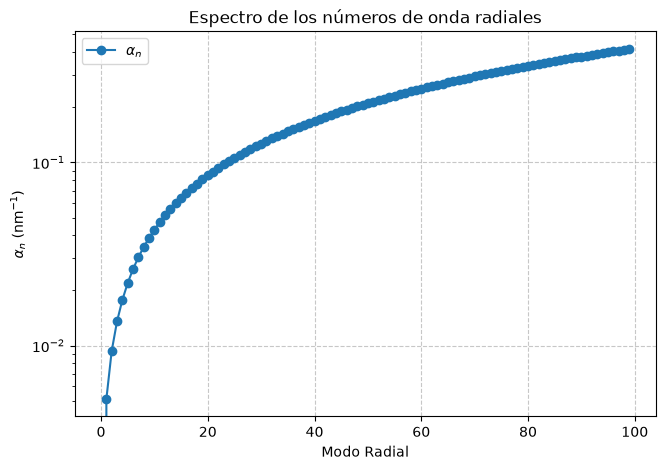

In [9]:
plt.figure(figsize=(7.5, 5))
plt.semilogy(alpha_n, 'o-', label=r"$\alpha_n$")
plt.xlabel('Modo Radial')
plt.ylabel(r'$\alpha_n$ (nm$^{-1}$)')
plt.title('Espectro de los números de onda radiales')
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/alpha_n.pdf', bbox_inches='tight')
plt.show()
plt.close()

In [10]:
def R_func(alpha, rho):
    """
    Calcula R_n(rho) = J0(alpha_n * rho) normalizados con la norma analítica
      ∫₀ᴿ J₀²(αₙ ρ) ρ dρ = (R²/2)[J₀²(αₙR) + J₁²(αₙR)].

    Args:
        alpha_n: array de raíces αₙ, shape (n_modes,)
        rho_vals: escalar o array de posiciones radiales, shape (m,)

    Returns:
        R_normed: array (n_modes, m) de los modos normalizados
        norms:    array (n_modes,) con el valor exacto de la norma
    """
   # 1) Aseguramos que alpha_n y rho_vals sean arrays 1D
    alpha_arr = np.atleast_1d(alpha)              # shape (n_modes,)
    rho_arr   = np.atleast_1d(rho)             # shape (m,)

    # 2) Creamos vistas 2D para broadcasting
    alpha = alpha_arr.reshape(-1, 1)                # (n_modes, 1)
    rho   = rho_arr.reshape(1, -1)                  # (1, m)

    # 3) Evaluamos el modo sin normalizar
    R_matrix = jv(0, alpha * rho)                   # (n_modes, m)

    # 4) Calculamos la norma analítica usando alpha_arr (no el escalar viejo)
    J0R = jv(0, alpha_arr * R)                      # (n_modes,)
    J1R = jv(1, alpha_arr * R)                    # (n_modes,)
    norms = 0.5 * R**2 * (J0R**2 + J1R**2)           # (n_modes,)

    # 5) Aseguramos que norms sea un array 1D
    norms = np.atleast_1d(norms)

    # 6) Factor de normalización
    N = 1.0 / np.sqrt(norms)                        # (n_modes,)

    # 7) Aplicamos normalización por filas
    R_normed = N[:, None] * R_matrix                # (n_modes, m)

    return R_normed, np.sqrt(norms)

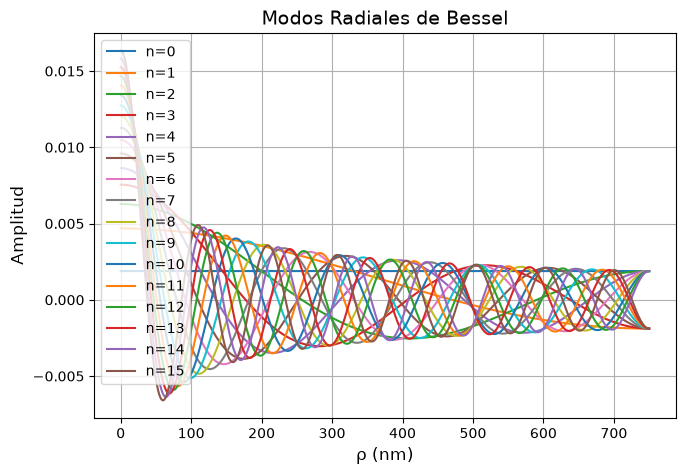

In [11]:
rho_nodes = np.linspace(0.0, R, N_r)
R_values,R_norms=R_func(alpha_n,rho_nodes)

# Graficar modos radiales
plt.figure(figsize=(7.5, 5))
for n in range(min(16, n_modes_radial)):
    plt.plot(rho_nodes, R_values[n], label=f"n={n}", linewidth=1.5)

plt.xlabel("ρ (nm)", fontsize=12)
plt.ylabel("Amplitud", fontsize=12)
plt.title("Modos Radiales de Bessel", fontsize=14)
plt.legend()
plt.grid(True)
plt.savefig("figuras/modos_radiales.pdf", bbox_inches="tight")
plt.show()
plt.close()

## Solución axial

Para cada modo radial $n$ la parte axial obedece el problema de Sturm–Liouville

$$-\frac{d}{dz}\left(D(z)\frac{dZ}{dz}\right)+\alpha_n^2D(z)Z=\Lambda Z,\qquad z\in[d,\,d+L]$$

donde $\Lambda_{n,m}$ (unidades de $\mu\mathrm{s}^{-1}$) es el autovalor compuesto que gobierna el decaimiento temporal $T(t)=e^{-\Lambda_{n,m}t}$.

### Discretización en volumen finito

Se integra la ecuación sobre la **celda de control** $[z_{j-1/2},z_{j+1/2}]$, de ancho

$$w_j=\frac{h_j+h_{j+1}}{2},\qquad h_j=z_j-z_{j-1}$$

de modo que el término difusivo se convierte en un balance exacto de flujos entre las interfases:

$$-\int_{z_{j-1/2}}^{z_{j+1/2}}\frac{d}{dz}\left(D\frac{dZ}{dz}\right)dz=-\left.D\frac{dZ}{dz}\right\vert_{j+1/2}+\left.D\frac{dZ}{dz}\right\vert_{j-1/2}\approx-\frac{D_{j+1/2}\left(Z_{j+1}-Z_j\right)}{h_{j+1}}+\frac{D_{j-1/2}\left(Z_j-Z_{j-1}\right)}{h_j}$$

Donde $D_{j+1/2}$ es el **promedio armónico** de $D$ en la interfaz entre nodos:

$$D_{j+\frac{1}{2}}=\frac{2\,D(z_j)\,D(z_{j+1})}{D(z_j)+D(z_{j+1})}$$

El promedio armónico conserva el flujo $J=-D\,dZ/dz$ a través de cada interfaz, que es la discretización consistente para el operador $d/dz[D(z)\,d/dz]$.

### Ensamblaje: problema generalizado simétrico

Agrupando, el sistema toma la forma $K\mathbf{Z}=\Lambda M\mathbf{Z}$ con $M=\operatorname{diag}(w_j)$ y $K$ **tridiagonal simétrica**:

$$K_{j,j}=\frac{D_{j-1/2}}{h_j}+\frac{D_{j+1/2}}{h_{j+1}}+\alpha_n^2D_jw_j,\qquad K_{j,j+1}=K_{j+1,j}=-\frac{D_{j+1/2}}{h_{j+1}}$$

Es importante **no** dividir cada fila por $w_j$ antes de ensamblar: eso produce la matriz $M^{-1}K$, que en una malla no uniforme **no es simétrica** ($M^{-1}K$ tiene $-D_{j+1/2}/(h_{j+1}w_j)$ arriba y $-D_{j+1/2}/(h_{j+1}w_{j+1})$ abajo) y por tanto no puede pasarse a un diagonalizador simétrico.

### Condiciones de contorno

Las celdas de los extremos son **medias celdas**, de ancho $w_0=h_1/2$ y $w_{N_z-1}=h_{N_z-1}/2$; el factor $1/2$ es esencial para que el esquema sea consistente.

#### Superficie ($z=d$, $j=0$): condición de Robin

El flujo que sale por $z=d$ es $\left.D\,dZ/dz\right\vert_{z=d}=\kappa Z_0$, con $\kappa\ge0$ la permeabilidad (adsorción). El balance en la media celda da

$$K_{0,0}=\frac{D_{1/2}}{h_1}+\kappa+\alpha_n^2D_0w_0,\qquad K_{0,1}=-\frac{D_{1/2}}{h_1}$$

El término $\kappa$ entra con signo **positivo**: aumentar la permeabilidad aumenta los autovalores, es decir acelera el decaimiento.

#### Borde superior ($z=d+L$, $j=N_z-1$): condición de Neumann

El borde superior es la truncación artificial del líquido semiinfinito, de modo que es **reflejante** (flujo nulo) y **no** lleva término $\kappa$:

$$K_{N_z-1,N_z-1}=\frac{D_{N_z-3/2}}{h_{N_z-1}}+\alpha_n^2D_{N_z-1}w_{N_z-1},\qquad K_{N_z-2,N_z-1}=-\frac{D_{N_z-3/2}}{h_{N_z-1}}$$

### Resolución

El problema generalizado se reduce a uno estándar mediante la similitud

$$A=M^{-1/2}KM^{-1/2},$$

que conserva la simetría y el espectro. $A$ es tridiagonal simétrica y se diagonaliza con `scipy.linalg.eigh_tridiagonal` seleccionando los $m_{\max}$ autovalores más bajos. Los autovectores físicos se recuperan como $\mathbf{Z}=M^{-1/2}\mathbf{v}$ y quedan ortonormales respecto al producto $\sum_j w_j Z_jZ'_j$, que es exactamente la regla del trapecio para $\int Z Z'\,dz$.

> **Verificación.** Con $\kappa=0$ y $\alpha_0=0$ el operador debe anular la función constante (conservación de masa), de modo que $\Lambda_{0,0}=0$. Esta comprobación se imprime al ejecutar la celda y es la que detecta cualquier error de ensamblaje en las filas de frontera.

In [12]:
##############################################################################
# 5. Solución Axial Z(z)  —  discretización en volumen finito
##############################################################################
# Para cada modo radial n hay que resolver el problema de Sturm-Liouville
#
#     -d/dz( D(z) dZ/dz ) + alpha_n^2 D(z) Z = Lambda Z,     z in [d, d+L]
#
# Se integra sobre la celda [z_{j-1/2}, z_{j+1/2}], de ancho w_j, y se usa la
# media armónica de D en las interfases (conserva el flujo J = -D dZ/dz).
# Resulta el problema generalizado SIMÉTRICO  K Z = Lambda M Z,  M = diag(w_j):
#
#     K_{j,j+1} = K_{j+1,j} = -D_{j+1/2} / h_j
#     K_{j,j}   = D_{j-1/2}/h_{j-1} + D_{j+1/2}/h_j + alpha_n^2 D_j w_j
#
# con las celdas de frontera de ancho w_0 = h_0/2 y w_{N-1} = h_{N-2}/2:
#
#     z = d      (Robin):   K_{0,0}     = D_{1/2}/h_0 + varkappa + alpha^2 D_0 w_0
#     z = d + L  (Neumann): K_{N-1,N-1} = D_{N-3/2}/h_{N-2}      + alpha^2 D_{N-1} w_{N-1}
#
# Los w_j son exactamente los pesos de la regla del trapecio, de modo que la
# ortonormalidad discreta  sum_j w_j Z_j^2 = 1  coincide con  ∫ Z^2 dz = 1.
#
# El sistema se simetriza con la similitud  A = M^{-1/2} K M^{-1/2}, que es
# tridiagonal simétrica, y se diagonaliza con `eigh_tridiagonal`.
#
# Esto corrige tres defectos del ensamblado anterior:
#   (1) `lower_diag[-2]` escribía A[N-2,N-3] en vez de A[N-1,N-2]: la última
#       fila quedaba desacoplada del resto (bloque 1x1 con autovalor espúreo
#       D/h_L^2) y el operador dejaba de conservar la masa;
#   (2) las filas de frontera dividían por h_0 en vez de por el ancho real de
#       celda h_0/2, lo que hacía la condición de contorno inconsistente y
#       reducía varkappa a la mitad;
#   (3) varkappa se aplicaba también en z = d+L, donde el modelo pide Neumann.
# Además evita ARPACK en modo shift-invert con sigma=0 sobre una matriz
# singular (el modo uniforme tiene autovalor nulo), que no convergía: daba un
# espectro distinto para cada sigma y no se estabilizaba al refinar la malla.
#
# Comprobación: con varkappa = 0 y alpha_0 = 0 el operador debe anular la
# función constante (conservación de masa), es decir Lambda_{0,0} = 0.

h = np.diff(z)
N_nodos = len(z)

# Anchos de celda = pesos de la regla del trapecio
w_cell = np.empty(N_nodos)
w_cell[1:-1] = 0.5 * (h[:-1] + h[1:])
w_cell[0]    = 0.5 * h[0]
w_cell[-1]   = 0.5 * h[-1]

# Media armónica de D en las interfases j+1/2
D_half = 2.0 * D_values[:-1] * D_values[1:] / (D_values[:-1] + D_values[1:])

# Parte de K que no depende de alpha_n
K_off_0 = -D_half / h                                   # K[j, j+1] = K[j+1, j]
K_dia_0 = np.zeros(N_nodos)
K_dia_0[1:-1] = D_half[:-1] / h[:-1] + D_half[1:] / h[1:]
K_dia_0[0]    = D_half[0] / h[0] + varkappa             # Robin en z = d
K_dia_0[-1]   = D_half[-1] / h[-1]                      # Neumann en z = d + L

inv_sqrt_w = 1.0 / np.sqrt(w_cell)


def build_system(n):
    """
    Resuelve la parte axial para el modo radial n.

    Args:
        n (int): Índice del modo radial.

    Returns:
        (n, (evals, evecs)) con evals los m_max autovalores Lambda_{n,m} más
        bajos y evecs (N_nodos, m_max) los modos normalizados: ∫ Z^2 dz = 1.
    """
    alpha = alpha_n[n]

    diag = (K_dia_0 + alpha**2 * D_values * w_cell) * inv_sqrt_w**2
    offd = K_off_0 * inv_sqrt_w[:-1] * inv_sqrt_w[1:]

    evals, V = eigh_tridiagonal(diag, offd, select='i',
                                select_range=(0, m_max - 1))

    # Vuelta a la variable física y normalización con los pesos de celda
    evecs = V * inv_sqrt_w[:, None]
    evecs /= np.sqrt(np.einsum('j,jm,jm->m', w_cell, evecs, evecs))[None, :]

    # El operador es semidefinido positivo; recorta el cero numérico
    evals = np.maximum(evals, 0.0)

    return (n, (evals, evecs))


axial_results = Parallel(n_jobs=4, verbose=1)(delayed(build_system)(n) for n in range(n_modes_radial))
eigenvalues_ax = {}
eigenvectors_ax = {}
for n, (evals, evecs) in sorted(axial_results, key=lambda x: x[0]):
    eigenvalues_ax[n] = evals
    eigenvectors_ax[n] = evecs
del axial_results   # libera los ~7 GB que retiene la lista de resultados

print(f"Lambda_(0,0) = {eigenvalues_ax[0][0]:.3e} 1/us  "
      f"(debe ser 0 si varkappa = 0: modo uniforme conservado)")

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  1.3min


Lambda_(0,0) = 1.049e-07 1/us  (debe ser 0 si varkappa = 0: modo uniforme conservado)


[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  3.1min finished


In [13]:
# Apilado en (n_modes_radial, m_max, N_z). Se copia modo a modo y se libera la
# entrada del diccionario sobre la marcha: construir el array con una
# comprension mantendria viva a la vez la lista y el resultado (~14 GB para
# 100 x 100 x 90 000 en float64).
_evals = np.empty((n_modes_radial, m_max))
_evecs = np.empty((n_modes_radial, m_max, len(z)))
for n in range(n_modes_radial):
    _evals[n, :] = eigenvalues_ax[n]
    _evecs[n, :, :] = eigenvectors_ax.pop(n).T   # (N_z, m_max) -> (m_max, N_z)
eigenvalues_ax = _evals
eigenvectors_ax = _evecs
del _evals, _evecs

print(f"eigenvectors_ax: {eigenvectors_ax.shape}, "
      f"{eigenvectors_ax.nbytes/1e9:.2f} GB")

eigenvectors_ax: (100, 100, 90000), 7.20 GB


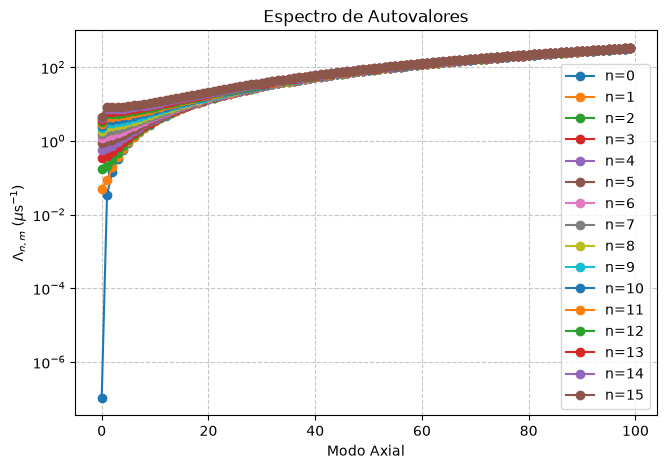

In [14]:
# Graficar espectro de autovalores
plt.figure(figsize=(7.5,5))
for n in range(min(16,n_modes_radial)):
    evals = eigenvalues_ax[n]
    plt.semilogy(evals, 'o-', label=f'n={n}')
plt.xlabel('Modo Axial')
plt.ylabel(r'$\Lambda_{n,m}$ ($\mu$s$^{-1}$)')
plt.title('Espectro de Autovalores')
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/eigenvalues.pdf', bbox_inches='tight')
plt.show()
plt.close()

In [15]:
# Comprobación de la normalización axial.
#
# `build_system` ya devuelve los modos con ∫Z² dz = 1, usando los pesos de celda
# w_j, que son exactamente los de la regla del trapecio. Aquí sólo se verifica.
#
# Se hace modo radial a modo radial: `np.trapezoid(eigenvectors_ax**2, ...)`
# sobre el array completo crearía un temporal de ~7 GB. (Antes se evitaba con
# .astype(np.float32), que además perdía ~7 cifras significativas en la norma.)
desv_max = 0.0
for n in range(n_modes_radial):
    norms_n = np.sqrt(np.trapezoid(eigenvectors_ax[n]**2, z, axis=1))  # (m_max,)
    desv_max = max(desv_max, np.abs(norms_n - 1.0).max())

print(f"desviación máxima de ∫Z² dz respecto a 1: {desv_max:.3e}")

desviación máxima de ∫Z² dz respecto a 1: 3.997e-15


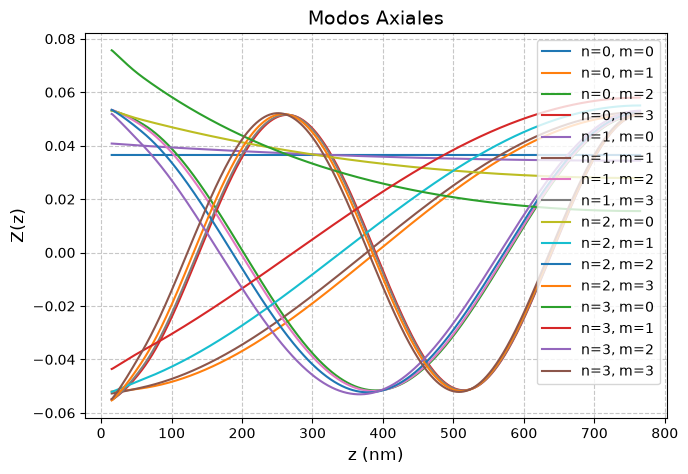

In [16]:
# Graficar algunos modos axiales
plt.figure(figsize=(7.5,5))
for n in range(4): # range(min(3, n_modes_radial)):
    for m in range(4):
        plt.plot(z, eigenvectors_ax[n][m,:], label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel("z (nm)", fontsize=12)
plt.ylabel("Z(z)", fontsize=12)
plt.title("Modos Axiales", fontsize=14)
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig("figuras/modos_axiales.pdf", bbox_inches="tight")
plt.show()
plt.close()

## Solución temporal

Se tiene que esta debe ser constante, por lo que se toma $-\Lambda$, lo que permite plantear la ecuación:
    
$$\frac{1}{T}\frac{dT}{dt}=-\Lambda$$

De forma que al resolver la ecuación, se obtiene la solución:

$$T=\sum_{n=1}^{N_\rho}\sum_{m=1}^{M_z}T_{n,m}\exp{\left(-\Lambda_{n,m}t\right)}$$

Donde $\Lambda_{n,m}$ es el autovalor compuesto del operador axial (unidades $\mu\mathrm{s}^{-1}$), que ya incorpora el término $\alpha_n^2D(z)$ del modo radial.

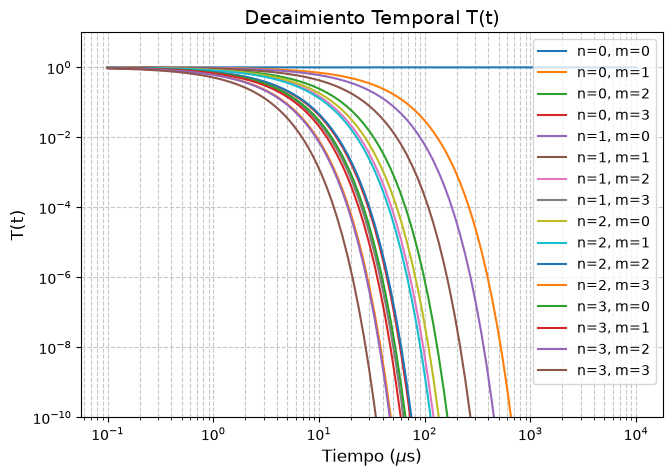

In [17]:
##############################################################################
### # 6. Término Temporal T(t)
##############################################################################
# Ahora, para cada eigenvalor (de la parte axial) usaremos el valor absoluto
# para que T(t)=exp(-|λ| t) decaiga.
def T(t, lam):
    return np.exp(-np.abs(lam) * t)

# Graficamos T(t) para los modos del sistema axial
plt.figure(figsize=(7.5,5))
t_plot = np.logspace(-1, 4, 100)
for n in range(min(4,n_modes_radial)):
    for m in range(min(4, m_max)):
        lam = eigenvalues_ax[n][m]
        plt.loglog(t_plot, T(t_plot, lam), label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel(r"Tiempo ($\mu$s)", fontsize=12)
plt.ylabel("T(t)", fontsize=12)
plt.ylim(1e-10,1e1)
plt.title("Decaimiento Temporal T(t)", fontsize=14)
plt.legend()
plt.grid(ls='--', alpha=0.7, which="both")
plt.savefig("figuras/T_t.pdf", bbox_inches="tight")
plt.show()
plt.close()

## Cálculo de los coeficientes $A_{n,m}$

Los coeficientes de expansión $A_{n,m}$ se determinan a partir de la proyección de la condición inicial sobre las funciones $\mathcal{R}(\rho)$ y $Z(z)$, utilizando la ortogonalidad de las funciones propias:

$$\frac{\langle P(\rho,z,0),J_0(\alpha_n\rho)Z_{n,m}(z)\rangle}{\mathcal{N}_n\mathcal{M}_{n,m}}$$

Lo que nos da como resultado la expresión:

$$A_{n,m} = \frac{J_0(\alpha_n \rho_0) Z_{n,m}(z_0)}{2\pi\mathcal{N}_n \mathcal{M}_{n,m}}$$

Donde:
- **La norma radial:** se obtiene a partir de la ortogonalidad de las funciones de Bessel. La fórmula general es:
  $$\mathcal{N}_n = \sqrt{\int_0^R \rho J_0^2(\alpha_n \rho) d\rho}=\sqrt{\frac{R^2}{2}\left[J_0^2(\alpha_n R)+J_1^2(\alpha_n R)\right]}$$
  Con la condición de Neumann ($J_1(\alpha_n R)=0$, $\kappa=0$) esto se simplifica a $\mathcal{N}_n=\frac{R}{\sqrt{2}}|J_0(\alpha_n R)|$.
- **La norma axial:** No es necesario ponderar pues la forma de la ecuación de Sturm-Liouville indica que $r(x)=1$. La integral se calcula utilizando el método del trapecio. $$\mathcal{M}_{n,m} = \sqrt{\int_d^{d+L} Z_{n,m}^2(z)\, dz}$$

In [18]:
##############################################################################
# 7. Cálculo de Coeficientes A_{nm}
##############################################################################
# Se asume que la condición inicial es:
#     P(ρ, z, 0) ∝ δ(ρ-ρ0) δ(z-z0) / (2πρ0)

# --- Parámetros de la delta ---
rho0, z0 = 0.0,  d  # centro (nm)

# --- 1) Mallado de cuadratura cilíndrica (ρ, z) ---
N_quad = 1000
rho_quad = np.linspace(0.0, R, N_quad)   # nodos radiales
z_quad   = np.linspace(d, L+d, N_quad)   # nodos axiales

# (1) Evaluar modos radiales en rho0:
#     R_func(alpha_n, x) devuelve R_mat[n,i] = R_n(x)
#     Usamos un punto x = rho0
a0 = np.array([rho0])                       # array de un punto
R0, _ = R_func(alpha_n, a0)                # R0.shape = (n_modes_radial, 1)
R0 = R0[:, 0]                              # ahora vector (n_modes_radial,)

# (2)-(3) Evaluar los modos axiales en z0 por interpolación cúbica.
#
#     Se construye un spline VECTORIAL por modo radial (sus m_max modos a la vez)
#     y se descarta en cuanto se ha evaluado. Guardar los n_modes_radial * m_max
#     = 10 000 splines escalares requeriría ~29 GB (cada uno almacena 4 x N_z
#     coeficientes), por lo que el cuaderno no llegaba a ejecutarse.
def eval_Z_at(z_val):
    Z_val = np.empty((n_modes_radial, m_max))
    for n in range(n_modes_radial):
        cs_n = CubicSpline(z, eigenvectors_ax[n].T, axis=0, extrapolate=False)
        Z_val[n, :] = cs_n(z_val)
    return Z_val

Z0 = eval_Z_at(z0)  # Z0.shape = (n_modes_radial, m_max)

# (4) Coeficientes modal A_nm: producto de R0 y Z0
#     A_nm_delta[n,m] = R_n(rho0) * Z_{n,m}(z0)
A_nm = R0[:, None] * Z0            # shape (n_modes_radial, m_max)
print(f"A_nm_delta shape: {A_nm.shape}")

A_nm_delta shape: (100, 100)


## Integración de la solución completa

La densidad de probabilidad final se reconstruye como superposición de todos los modos de las ecuaciones temporal y radial con la solución que se obtiene de forma numérica para la parte axial. De esta forma, se construye la solución de la ecuación inicial con coeficiente de difusión variable.

$$P(\rho,z,t) = \sum_{n=1}^{N_\rho} \sum_{m=1}^{M_z} A_{n,m} J_0(\alpha_n \rho) Z_{n,m}(z) e^{-\Lambda_{n,m} t},$$

donde $N_\rho$ y $M_z$ se eligen para garantizar convergencia.

In [19]:
##############################################################################
# 8. Densidad de Probabilidad P(ρ,z,t)
##############################################################################
# Mallas de cuadratura para las integrales modales F_nm.
#
# El integrando f = (2z^2 - rho^2)/r^5 esta muy concentrado cerca de
# (rho, z) = (0, d): en z decae como z^-3 y los modos axiales tienen capa
# limite en la superficie. Con una malla uniforme de 1000 nodos y una suma
# rectangular (dr*dz*sum), la suma modal (5/16pi) sum F_nm^2 llegaba a valer
# un 111 % de la integral directa (5/16pi) int f^2 rho drho dz -- imposible
# para una identidad de Parseval truncada, que solo puede quedarse corta.
#
# Se usa la misma transformacion sinh de la malla axial para agrupar nodos en
# z = d, malla uniforme en rho (los modos radiales altos oscilan hasta rho = R)
# y pesos de la regla del trapecio en ambas direcciones.
N_quad = 2000
_s = np.arange(N_quad) / (N_quad - 1)

rho_nodes = np.linspace(0.0, R, N_quad)
z_nodes   = d + L * np.sinh(alpha_grid * _s) / np.sinh(alpha_grid)


def pesos_trapecio(x):
    """Pesos de la regla del trapecio para una malla posiblemente no uniforme."""
    h = np.diff(x)
    w = np.empty_like(x)
    w[1:-1] = 0.5 * (h[:-1] + h[1:])
    w[0]    = 0.5 * h[0]
    w[-1]   = 0.5 * h[-1]
    return w


w_rho = pesos_trapecio(rho_nodes)
w_z   = pesos_trapecio(z_nodes)

# Precompute Bessel J0 for all radial modes and rho
# J0_mat shape: (n_modes, Nr)
R0_mat,_ = R_func(alpha_n, rho_nodes)

# Precompute axial modes Z_tens: shape (Nz, n_modes, m_max)

n_modes, m_max = eigenvalues_ax.shape
Z_tens = np.zeros((N_quad, n_modes, m_max))
for n in range(n_modes):
    # un spline vectorial por modo radial, evaluado y descartado (ver celda 27)
    cs_n = CubicSpline(z, eigenvectors_ax[n].T, axis=0, extrapolate=False)
    Z_tens[:, n, :] = cs_n(z_nodes)

In [20]:
R0_mat, _ = R_func(alpha_n, rho_nodes)  # shape (n_modes_radial, Nr)

In [21]:
def compute_P_vec(t, eigenvalues_ax, Z_tens, R0_mat, A_nm):
    """
    Computa P(ρ,z,t) más rápido usando matrices precalculadas.

    Parámetros:
    - t: escalar de tiempo
    - Z_tens: shape (Nz, n_modes_radial, m_max)
    - R0_mat: shape (n_modes_radial, N_r)
    - A_nm: coeficientes modales (n_modes_radial, m_max)

    Devuelve:
    - P: shape (Nz, Nr)
    """
    T_decay = T(t, eigenvalues_ax)  # (n_modes, m_max)
    W = A_nm * T_decay               # (n_modes, m_max)
    B = np.sum(Z_tens * W[None, :, :], axis=2)  # (Nz, n_modes)
    S = np.dot(R0_mat.T, B.T)  # (Nr, Nz)
    return S.T # np.maximum(S.T, 0)

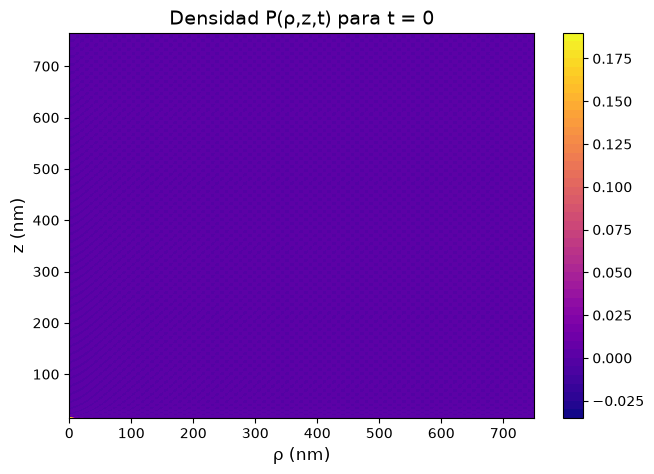

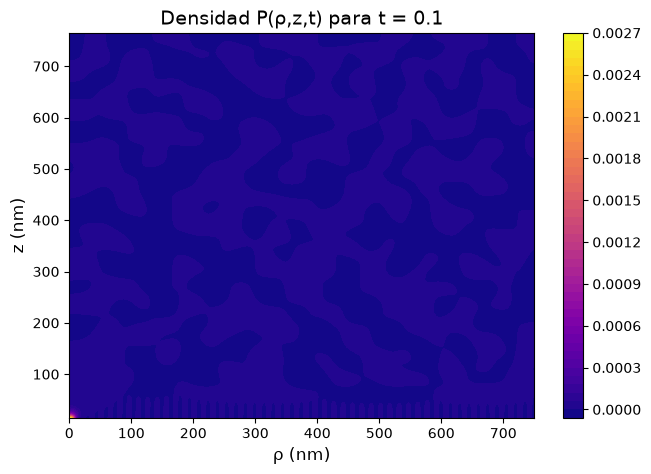

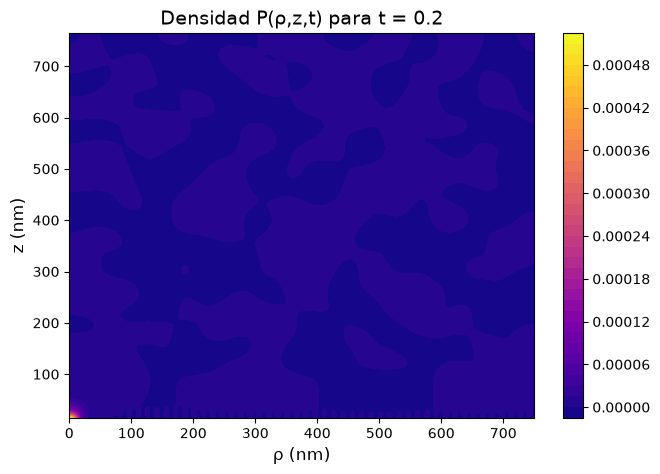

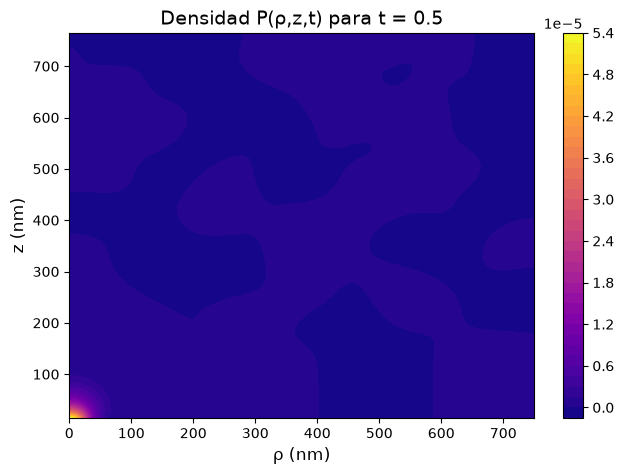

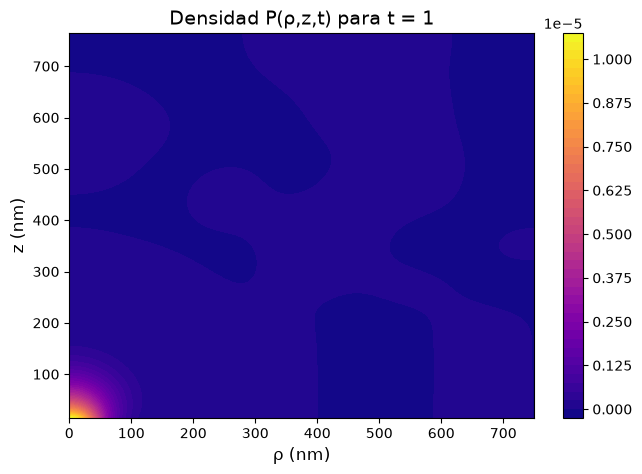

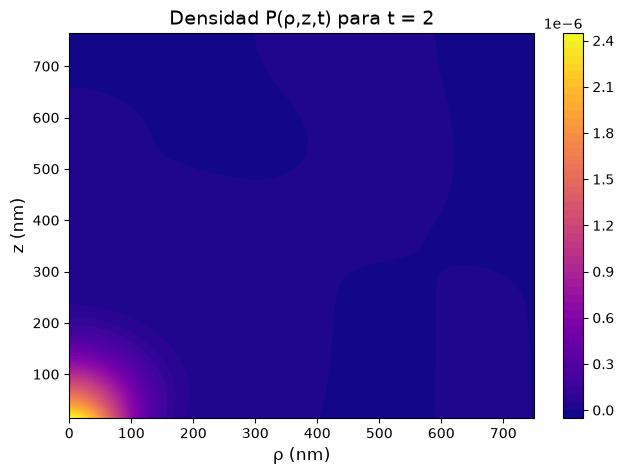

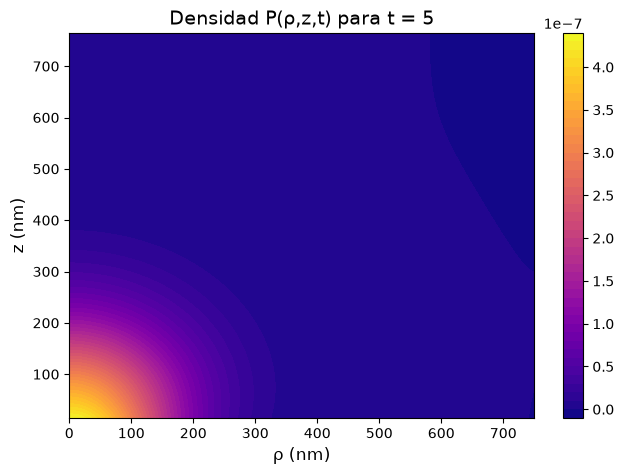

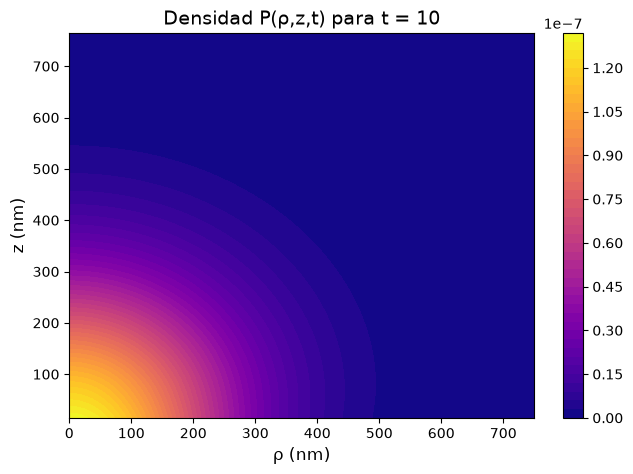

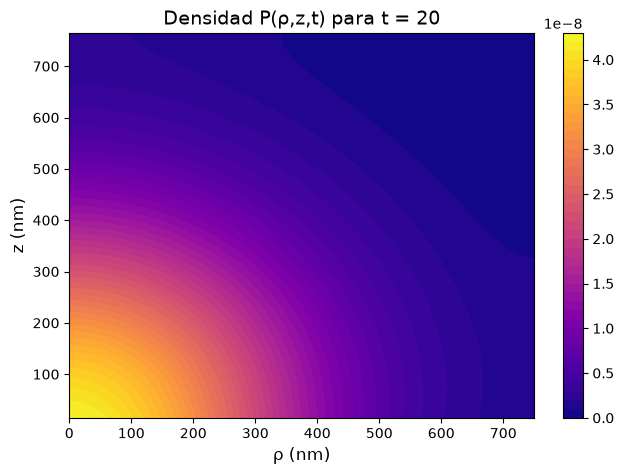

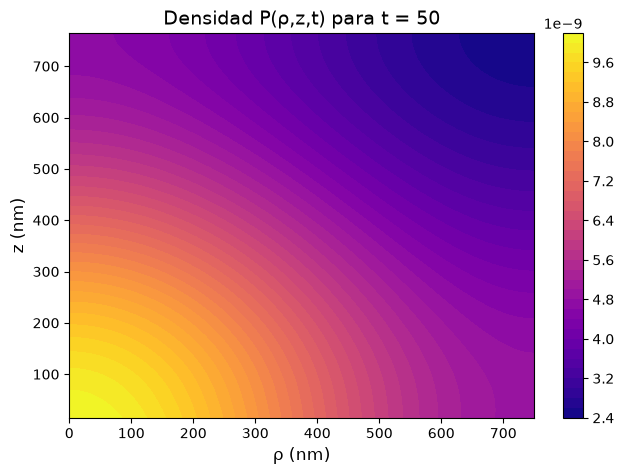

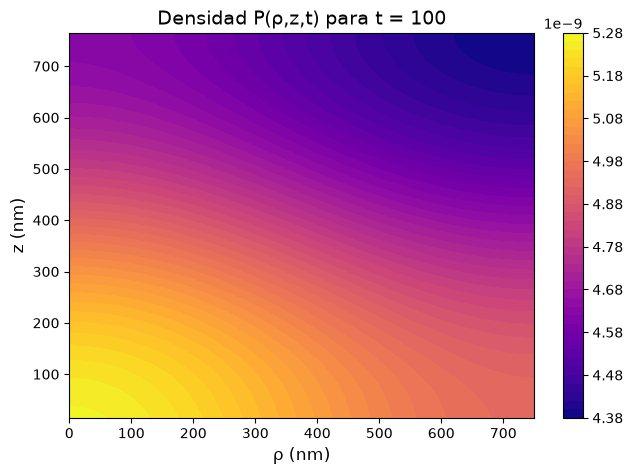

In [22]:
for t_val in [0,0.1,0.2,0.5,1,2,5,10,20,50,100]:
    P_val = compute_P_vec(t_val, eigenvalues_ax, Z_tens, R0_mat, A_nm)
    
    plt.figure(figsize=(7.5,5))
    plt.contourf(rho_nodes, z_nodes, P_val, 50, cmap="plasma")
    plt.xlabel("ρ (nm)", fontsize=12)
    plt.ylabel("z (nm)", fontsize=12)
    plt.title(f"Densidad P(ρ,z,t) para t = {t_val}", fontsize=14)
    plt.colorbar()
    plt.savefig(f"figuras/P_contour_{t_val}.pdf", bbox_inches="tight")
    plt.show()
    plt.close()

## Función de correlación $G(t)$

La función de correlación del campo magnético detectado por el sensor NV se define mediante:

$$G(t)=\langle B(t)B(0)\rangle\propto\int d^3\textbf{r}\int d^3\textbf{r}_0\, f(\textbf{r})f(\textbf{r}_0)P(\textbf{r},t\vert\textbf{r}_0,0)$$

donde el factor de forma dipolar

$$f(\textbf{r})\propto\frac{Y_2^0(\Omega)}{\rvert\textbf{r}\lvert^3}\quad\text{con}\quad Y_2^0(\theta)=\frac{1}{4}\sqrt{\frac{5}{\pi}}\left(3\cos^2{\theta}-1\right)$$

refleja la dependencia angular y radial de la interacción dipolar, siendo $\cos{\theta}=\frac{z}{\sqrt{\rho^2+z^2}}$ y $P(\textbf{r},t\vert\textbf{r}_0,0)$ el propagador de difusión con $D(z)$ variable.

En coordenadas cilíndricas, con $r^2=\rho^2+z^2$:

$$3\cos^2\theta-1=\frac{3z^2-r^2}{r^2}=\frac{2z^2-\rho^2}{\rho^2+z^2}\;\Longrightarrow\;f(\rho,z)=\frac{2z^2-\rho^2}{\left(\rho^2+z^2\right)^{5/2}}$$

> **Nota.** Conviene insistir en que el numerador es $3z^2-r^2=2z^2-\rho^2$ y **no** $3z^2-\rho^2$: la resta es contra $r^2$, no contra $\rho^2$. El kernel se anula en el ángulo mágico $\theta=\arccos(1/\sqrt3)\approx54.7^\circ$, y el prefactor $5/16\pi$ de $G(t)$ es precisamente $\left[\tfrac14\sqrt{5/\pi}\right]^2$, el cuadrado del coeficiente de $Y_2^0$. El mismo kernel aparece escrito como $W=\rho\left[3z^2/r^5-1/r^3\right]$ en `Sticky Walls Correlation/sticky-correlation-modal.ipynb`.

Por lo tanto, la integral se reduce a la expresión:

$$G(t)\propto\int_0^R\rho\, d\rho\int_d^{d+L}\!\!dz\int_0^R\rho_0\,d\rho_0\int_d^{d+L}\!\!dz_0\;\frac{\left(2z^2-\rho^2\right)}{\left(\rho^2+z^2\right)^{5/2}}\;\frac{\left(2z_0^2-\rho_0^2\right)}{\left(\rho_0^2+z_0^2\right)^{5/2}}\;P(\rho,z,t\vert\rho_0,z_0,0)$$

### Reducción a una suma modal

El propagador es separable en la base de autofunciones del operador de difusión,

$$P(\rho,z,t|\rho_0,z_0,0)\;\propto\;\sum_{n,m}\mathcal{R}_n(\rho)\,Z_{n,m}(z)\,\mathcal{R}_n(\rho_0)\,Z_{n,m}(z_0)\,e^{-\Lambda_{n,m}t}$$

con $\{\mathcal{R}_n\otimes Z_{n,m}\}$ ortonormal respecto a la medida $\rho\,d\rho\,dz$. Sustituyendo, la integral cuádruple **se factoriza exactamente** y queda

$$\boxed{\;G(t)=\frac{5}{16\pi}\sum_{n}\sum_{m}F_{n,m}^2\,e^{-\Lambda_{n,m}\,t}\;}$$

donde los **pesos modales dipolares** $F_{n,m}$ son la proyección de $f$ sobre cada modo:

$$F_{n,m}=\int_0^R\!\!\int_d^{d+L}f(\rho,z)\,\mathcal{R}_n(\rho)\,Z_{n,m}(z)\,\rho\,d\rho\,dz$$

Esta forma garantiza, por la identidad de Parseval, que

$$G(0)=B_{\rm rms}^2=\frac{5}{16\pi}\sum_{n,m}F_{n,m}^2\;\xrightarrow[\;n,m\to\infty\;]{}\;\frac{5}{16\pi}\int_0^R\!\!\int_d^{d+L}f^2\,\rho\,d\rho\,dz$$

independientemente de la condición inicial. La diferencia entre ambos miembros mide directamente el **error de truncamiento modal**, y es la comprobación que conviene reportar junto con el análisis de convergencia.

### Discretización de las integrales

$F_{n,m}$ se evalúa sobre una malla de cuadratura de $N_q$ nodos uniformes en $\rho\in[0,R]$ y en $z\in[d,d+L]$, contrayendo primero en $\rho$ y después en $z$:

$$F_{n,m}\approx\Delta\rho\,\Delta z\sum_j\left[\sum_i\mathcal{R}_n(\rho_i)\,\rho_i\,f(\rho_i,z_j)\right]Z_{n,m}(z_j)$$

Los modos axiales $Z_{n,m}$, calculados sobre la malla sinh-adaptativa de $N_z$ nodos, se llevan a la malla de cuadratura mediante *splines* cúbicos.

In [23]:
##############################################################################
# 8. Función de Correlación G(t)
##############################################################################

# Precomputar factor dipolar f(rho,z) sobre toda la malla  (Nr x Nz)
#
#   f = (3 cos^2(theta) - 1) / r^3,  cos(theta) = z/r,  r^2 = rho^2 + z^2
#     = (3 z^2 - r^2) / r^5
#     = (2 z^2 - rho^2) / (rho^2 + z^2)^{5/2}
#
# El prefactor 5/(16 pi) de G(t) es el cuadrado del coeficiente de
# Y_2^0 = (1/4) sqrt(5/pi) (3 cos^2 theta - 1), de modo que f tiene que ser
# ese mismo armonico. Antes estaba escrito (3 z^2 - rho^2), que corresponde a
# sustituir r^2 -> rho^2 en 3z^2 - r^2; el kernel correcto ya aparece en
# 'Sticky Walls Correlation/sticky-correlation-modal.ipynb' como
# W = rho [3z^2/r^5 - 1/r^3].
#
# z_nodes ya empieza en d (distancia NV), no se suma d de nuevo.
R2 = rho_nodes**2
Z2 = z_nodes**2
f_mat = (2*Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5  # (Nr, Nz)

In [24]:
##############################################################################
# G(t) formula modal exacta: G(t) = (5/16pi) sum_{n,m} F_nm^2 exp(-Lambda_nm t)
# (Lambda_nm es el autovalor del operador axial, en 1/us)
# F_nm = integral f(r) R_n(rho) Z_nm(z) rho drho dz  (proyeccion dipolar)
# Con esta formula G(0) = B_rms^2 = (5/16pi) sum F_nm^2 exactamente.
##############################################################################

# Paso 1: R_rho[n,i] = R_n(rho_i) * rho_i * w_rho_i   (incluye la medida y el peso)
R_rho = R0_mat * (rho_nodes * w_rho)[None, :]      # (n_modes, Nr)

# Paso 2: B_nj[n,j] = sum_i R_rho[n,i] * f_mat[i,j]   (contraccion en rho)
B_nj = np.dot(R_rho, f_mat)                        # (n_modes, Nz)

# Paso 3: F_nm[n,m] = sum_j w_z_j * B_nj[n,j] * Z_tens[j,n,m]  (contraccion en z)
F_nm_correct = np.zeros((n_modes_radial, m_max))
for _n in range(n_modes_radial):
    F_nm_correct[_n, :] = (B_nj[_n, :] * w_z) @ Z_tens[:, _n, :]   # (Nz,)@(Nz,m_max)

# B_rms^2 = G(0) = (5/16pi) sum F_nm^2
B_rms_sq = (5 / (16 * np.pi)) * np.sum(F_nm_correct**2)
print(f"B_rms^2 = {B_rms_sq:.6e}  ->  B_rms = {np.sqrt(abs(B_rms_sq)):.6e} nm^(-3)")

# Control de truncamiento por Parseval: la suma modal no puede superar a la
# integral directa; la diferencia es exactamente lo que se pierde al truncar.
B_rms_directo = (5 / (16 * np.pi)) * np.einsum('i,j,ij->',
                                               rho_nodes * w_rho, w_z, f_mat**2)
print(f"(5/16pi) * int f^2 rho drho dz = {B_rms_directo:.6e}")
print(f"capturado por {n_modes_radial}x{m_max} modos = "
      f"{100 * B_rms_sq / B_rms_directo:.2f} %  (debe ser <= 100 %)")

t_values = np.logspace(-4, 7, 1000)
tau_values = D_eff * t_values / d**2
G_values = np.zeros_like(t_values)
for i, t_val in enumerate(t_values):
    T_decay = T(t_val, eigenvalues_ax)         # (n_modes, m_max)
    G_values[i] = (5 / (16 * np.pi)) * np.sum(F_nm_correct**2 * T_decay)

print(f"G(t_min) = {G_values[0]:.6e}  (debe aprox. B_rms^2 = {B_rms_sq:.6e})")
np.savetxt("data/G_vs_t.dat", np.c_[t_values, G_values], header="Tiempo(us) G(t)", fmt="%.9e")

B_rms^2 = 3.680453e-06  ->  B_rms = 1.918451e-03 nm^(-3)
(5/16pi) * int f^2 rho drho dz = 3.682878e-06
capturado por 100x100 modos = 99.93 %  (debe ser <= 100 %)
G(t_min) = 3.677284e-06  (debe aprox. B_rms^2 = 3.680453e-06)


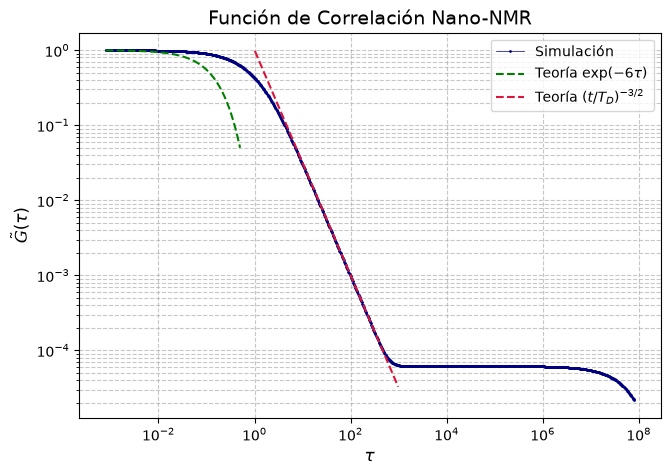

In [25]:
plt.figure(figsize=(7.5,5))
plt.loglog(tau_values, G_values/G_values[0], "o-", label="Simulación", color="navy", markersize=1, linewidth=0.5)
plt.plot(tau_values[tau_values<0.5], np.exp(-6*tau_values[tau_values<0.5]), "--", label=r"Teoría $\exp(-6\tau)$", color="green", linewidth=1.5)
plt.plot(tau_values[(tau_values>=1)&(tau_values<=1000)], (tau_values[(tau_values>=1)&(tau_values<=1000)])**-1.5, "--", label=r"Teoría $(t/T_D)^{-3/2}$", color="crimson", linewidth=1.5)
# plt.xlabel("Tiempo (s)", fontsize=12)
plt.xlabel(r"$\tau$", fontsize=12)
plt.ylabel(r"$\tilde{G}(\tau)$", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.grid(which="both", ls='--', alpha=0.7)
plt.savefig("figuras/correlacion_nanoNMR.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()

## Análisis de truncamiento modal

In [26]:
modes_list = np.arange(5,105,5)

In [27]:
G_dict     = {}

for modes in modes_list:
    print(f"--- Truncando a {modes} modos ---")
    # 1) Subconjuntos de datos
    R0_mat_sub = R0_mat[:modes, :]               # (modes, Nr)
    evals_sub  = eigenvalues_ax[:modes, :modes]  # (modes, modes)
    Z_tens_sub = Z_tens[:, :modes, :modes]       # (Nquad, modes, modes)

    # 2) F_nm para este subconjunto de modos
    R_rho_sub = R0_mat_sub * (rho_nodes * w_rho)[None, :]  # (modes, Nr)
    B_nj_sub  = np.dot(R_rho_sub, f_mat)                   # (modes, Nz)
    F_nm_sub  = np.zeros((modes, modes))
    for _n in range(modes):
        F_nm_sub[_n, :] = (B_nj_sub[_n, :] * w_z) @ Z_tens_sub[:, _n, :]

    # 3) G(t) = (5/16pi) sum F_nm_sub^2 exp(-Lambda t)
    G_vals = np.zeros_like(t_values)
    for i, t in enumerate(t_values):
        T_decay = np.exp(-np.abs(evals_sub) * t)
        G_vals[i] = (5/(16*np.pi)) * np.sum(F_nm_sub**2 * T_decay)
    G_dict[modes] = G_vals

--- Truncando a 5 modos ---
--- Truncando a 10 modos ---
--- Truncando a 15 modos ---
--- Truncando a 20 modos ---
--- Truncando a 25 modos ---
--- Truncando a 30 modos ---
--- Truncando a 35 modos ---
--- Truncando a 40 modos ---
--- Truncando a 45 modos ---
--- Truncando a 50 modos ---
--- Truncando a 55 modos ---
--- Truncando a 60 modos ---
--- Truncando a 65 modos ---
--- Truncando a 70 modos ---
--- Truncando a 75 modos ---
--- Truncando a 80 modos ---
--- Truncando a 85 modos ---
--- Truncando a 90 modos ---
--- Truncando a 95 modos ---
--- Truncando a 100 modos ---


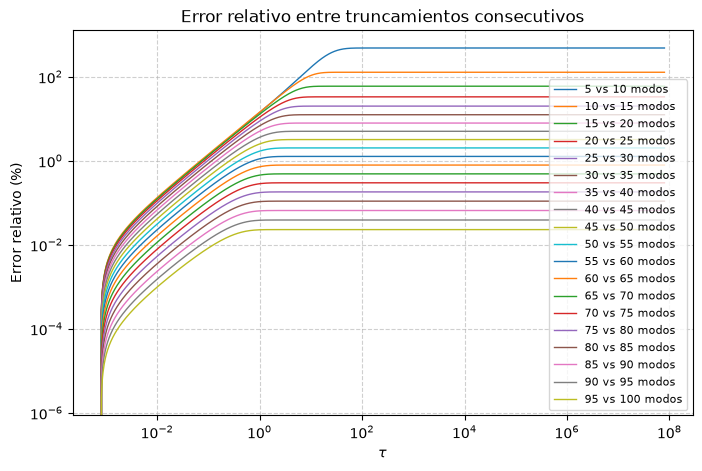

In [28]:
plt.figure(figsize=(8,5))
for i in range(len(modes_list)-1):
    m0, m1 = modes_list[i], modes_list[i+1]
    err = np.abs(G_dict[m0]/G_dict[m0][0] - G_dict[m1]/G_dict[m1][0]) / (G_dict[m1]/G_dict[m1][0]) * 100
    plt.loglog(tau_values, err, label=f"{m0} vs {m1} modos", linewidth=1)

plt.xlabel(r"$\tau$")
# plt.ylim((1,100))
plt.ylabel("Error relativo (%)")
plt.title("Error relativo entre truncamientos consecutivos")
plt.legend(fontsize=8)
plt.grid(which="both", ls='--', alpha=0.6)
plt.savefig("figuras/error_vs_t.pdf", bbox_inches="tight", dpi=300)
plt.show()

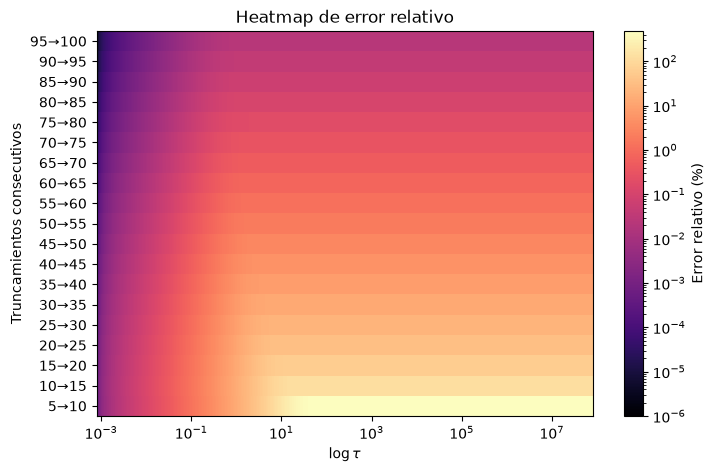

In [29]:
# 3.1. Construye la matriz de errores E (shape N_pairs × N_t)
E = []
labels = []
for i in range(len(modes_list)-1):
    m0, m1 = modes_list[i], modes_list[i+1]
    err = np.abs(G_dict[m0]/G_dict[m0][0] - G_dict[m1]/G_dict[m1][0]) / (G_dict[m1]/G_dict[m1][0]) * 100
    E.append(err)
    labels.append(f"{m0}→{m1}")
E = np.array(E)

# 3.2. Prepara los “bin edges” de tiempo en log
#    pcolormesh necesita los bordes de las celdas:
tau_edges = np.logspace(np.log10(tau_values[0]), np.log10(tau_values[-1]), len(tau_values)+1)
y_edges = np.arange(len(labels)+1)

# 3.3. Dibuja
plt.figure(figsize=(8,5))
mesh = plt.pcolormesh(tau_edges, y_edges, E, norm=LogNorm(vmin=E.min()+1e-6, vmax=E.max()),
                      cmap="magma")
plt.xscale("log")
plt.yticks(np.arange(0.5, len(labels)+0.5), labels)
plt.xlabel(r"$\log\tau$")
plt.ylabel("Truncamientos consecutivos")
plt.title("Heatmap de error relativo")
plt.colorbar(mesh, label="Error relativo (%)")
plt.savefig("figuras/heatmap_error.pdf", bbox_inches="tight", dpi=300)
plt.show()

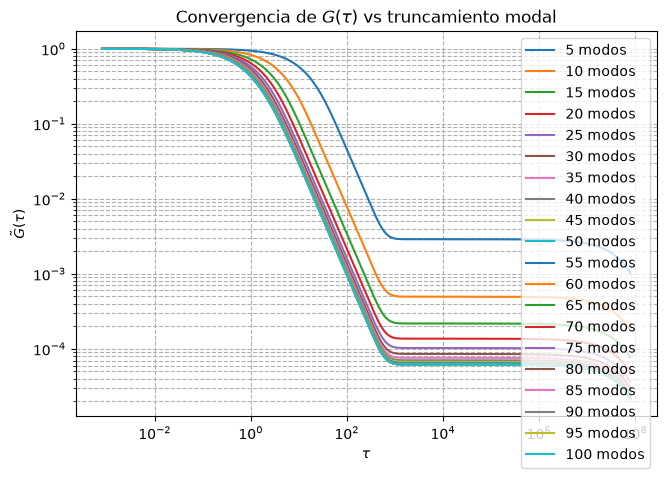

In [30]:
plt.figure(figsize=(7.5,5))
for modes in modes_list:
    Gv = G_dict[modes]
    plt.loglog(tau_values,
               Gv / Gv[0],
               label=f"{modes} modos")
plt.xlabel(r"$\tau$")
plt.ylabel(r"$\tilde G(\tau)$")
plt.title(r"Convergencia de $G(\tau)$ vs truncamiento modal")
plt.legend()
plt.grid(which="both", ls="--")
plt.savefig("figuras/convergencia_correlacion.pdf", bbox_inches="tight", dpi=300)
plt.show()

## Conclusiones

La función de correlación $\tilde{G}(\tau)$ calculada reproduce los dos regímenes universales esperados para difusión 3D cerca de una pared:

- **Régimen de tiempos cortos** ($\tau \ll 1$): la correlación decae como $\exp(-6\tau)$, característico de la difusión libre antes de que las moléculas "sientan" la pared.
- **Régimen de tiempos largos** ($\tau \gg 1$): el decaimiento sigue la ley de potencias $\tau^{-3/2}$, la firma del confinamiento tridimensional.

La malla sinh-adaptativa con 90 000 nodos concentra la resolución en la capa superficial $z \approx d$, donde $D(z)$ varía más rápidamente. La convergencia modal fue verificada con el análisis de truncamiento (5 a 100 modos): con 50–100 modos el error relativo es inferior al 1% en todo el rango de $\tau$. El modelo con perfil $D(z)$ inhomogéneo muestra desviaciones respecto al caso homogéneo que son sensibles a los parámetros $\lambda$, $\delta$ y $z_c$, explorados en los cuadernos de barrido paramétrico.